### Tutoriel CNN avec classification sur le dataset MNIST

Dans ce tutoriel, on va voir comment faire de la classification d'images avec l'exemple du dataset MNIST.

Commençons par télécharger le dataset MNIST afin de pouvoir l'utiliser. 

In [ ]:
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader, random_split
import torch 

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)

train_dataset = datasets.MNIST("../../../data", train = True, download = True, transform = ToTensor())
test_dataset = datasets.MNIST("../../../data",  train = False, download = True, transform = ToTensor())


train_dataset, val_dataset = random_split(
    train_dataset, [50000, 10000] 
)
train_loader = DataLoader(train_dataset, batch_size = 64)
val_loader = DataLoader(val_dataset, batch_size = 64)
test_loader = DataLoader(test_dataset, batch_size = 64)

In [6]:
images, labels = next(iter(train_loader))

import matplotlib.pyplot as plt 

fig, axs = plt.subplots(4, 4, figsize = (4 * 4, 4*4))

for i, ax in enumerate(axs.flatten()):
    ax.imshow(images[i].squeeze(), cmap = "gray")
    ax.set_title(f"Label {labels[i]}")


Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/home/mr-human/Desktop/school/science/teaching/.venv/lib64/python3.11/site-packages/IPython/core/interactiveshell.py", line 3823, in run_code
  File "/tmp/ipykernel_18397/3890997959.py", line 3, in <module>
    import matplotlib.pyplot as plt
  File "/home/mr-human/Desktop/school/science/teaching/.venv/lib64/python3.11/site-packages/matplotlib/__init__.py", line 1292, in <module>
    rcParams['backend'] = os.environ.get('MPLBACKEND')
    ~~~~~~~~^^^^^^^^^^^
  File "/home/mr-human/Desktop/school/science/teaching/.venv/lib64/python3.11/site-packages/matplotlib/__init__.py", line 784, in __setitem__
    raise ValueError(f"Key {key}: {ve}") from None
ValueError: Key backend: 'module://matplotlib_inline.backend_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 

### Création du réseau de neurones. 

Notre objectif va maintenant être de construire un réseau de neurones qui va prendre en entrée une image de MNIST et donner en sortie un vecteur de probabilités. 

On va utiliser pour ça un réseau de neurones de type multi-layer perceptron. 

In [7]:
from torch import nn 
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()

        self.mlp_layers = nn.Sequential(
            nn.Linear(int(28 * 28), 32),
            nn.SiLU(inplace = True),
            nn.Linear(32, 32), 
            nn.SiLU(inplace = True),
            nn.Linear(32, 10)
        )

    def forward(self, x):
        x = x.flatten(start_dim = 1)
        logits = self.mlp_layers(x)
        return logits 

net = MLP()
net(images).shape

torch.Size([64, 10])

In [24]:
from torch.nn.functional import one_hot
from tqdm import tqdm 
from torch.optim import Adam, SGD
from torch.nn import CrossEntropyLoss
import torch 

net = MLP()
loss_fn = CrossEntropyLoss()
optimizer = Adam(net.parameters(), lr = 1e-3)

train_losses = []
val_losses = []
epochs = 15
for epoch in tqdm(range(epochs)):
    for batch in train_loader:
        x, y = batch
        optimizer.zero_grad()

        y = one_hot(y, num_classes = 10).to(torch.float32)
        y_pred = net(x)
        loss = loss_fn(y_pred, y)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    with torch.no_grad():
        for batch in val_loader:
            x, y = batch
            y = one_hot(y, num_classes = 10).to(torch.float32)
            y_pred = net(x)
            loss = loss_fn(y_pred, y)
            val_losses.append(loss.item())

100%|██████████| 15/15 [01:28<00:00,  5.93s/it]


[Text(0, 0.5, 'Loss')]

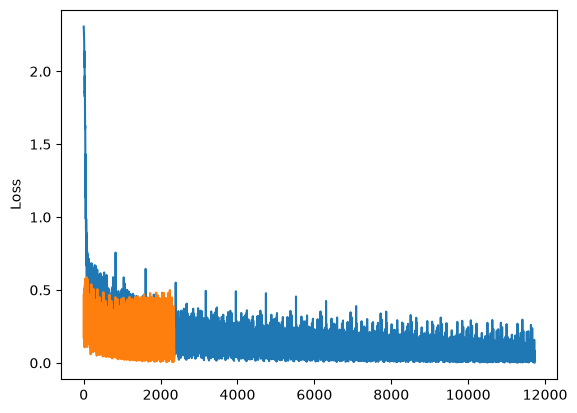

In [ ]:
plt.plot(train_losses, label = "Train loss")
plt.plot(val_losses, label = "Validation loss")
plt.gca().set(ylabel = "Loss")

### Performance check sur le dataset test  

In [26]:
test_images, test_labels = next(iter(test_loader))
predictions = net(test_images)
predictions = torch.argmax(predictions, dim = 1)

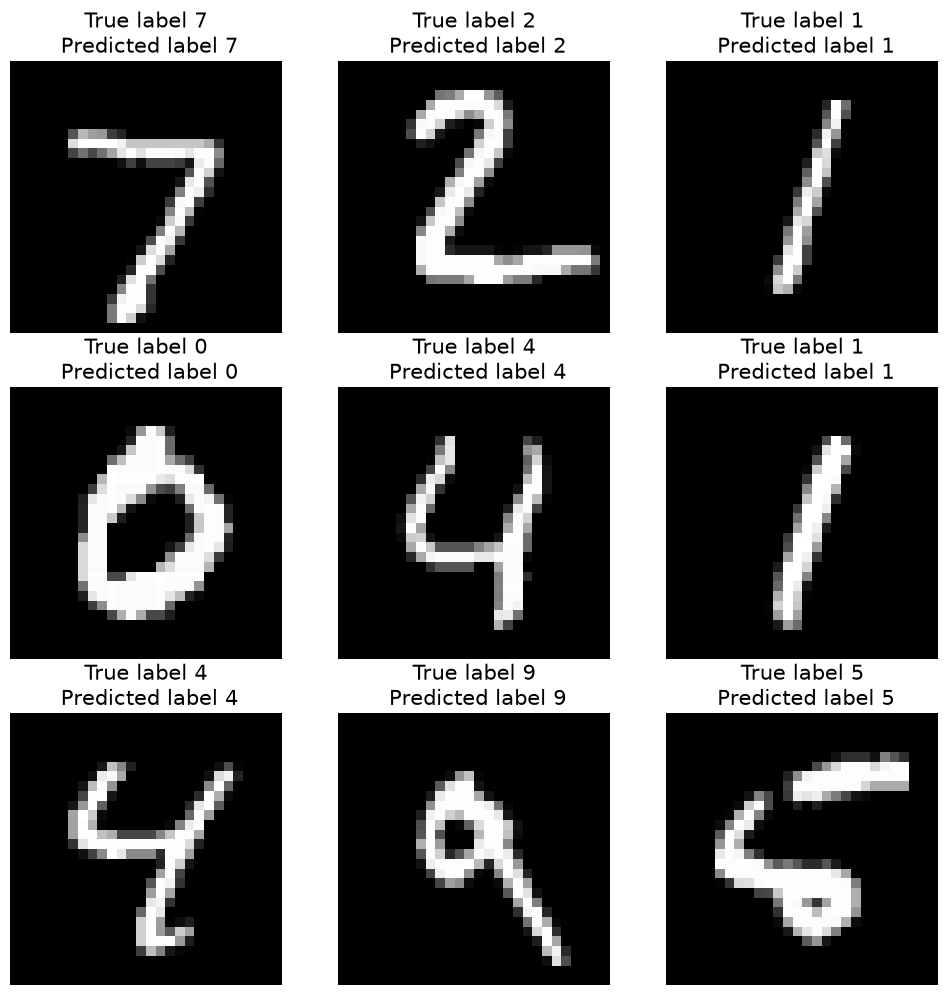

In [27]:
fig, axs = plt.subplots(3, 3, figsize = (4 * 3, 4 * 3))

for i, ax in enumerate(axs.flatten()):
    ax.imshow(test_images[i].squeeze(), cmap = "gray")
    ax.set_title(f"True label {test_labels[i]}\n Predicted label {predictions[i]}", fontsize = 15)
    ax.axis("off")



On peut visualiser la performance de manière plus quantitative.

In [4]:
import sklearn

In [3]:
!pip list

/bin/bash: /home/mr-human/Desktop/school/science/teaching/.venv/bin/pip: /home/mr-human/Desktop/Infosphere/science/teaching/.venv/bin/python3.11: bad interpreter: No such file or directory


In [80]:
from sklearn.metrics import ConfusionMatrixDisplay

all_predictions = []
all_labels = []

for x, y in test_loader: 
    y_pred = net(x)
    y_pred = y_pred.argmax(dim = 1)

    all_predictions.extend(y_pred.cpu().tolist())
    all_labels.extend(y.cpu().tolist())

ModuleNotFoundError: No module named 'sklearn'